In [6]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sys
import sklearn
import joblib

from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
pip install numpy pandas matplotlib seaborn scikit-learn joblib

   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.7 MB 6.7 MB/s eta 0:00:02
   -------- ------------------------------- 2.6/12.7 MB 6.6 MB/s eta 0:00:02
   -------------- ------------------------- 4.5/12.7 MB 7.3 MB/s eta 0:00:02
   ------------------ --------------------- 5.8/12.7 MB 7.1 MB/s eta 0:00:01
   ---------------------- ----------------- 7.1/12.7 MB 7.0 MB/s eta 0:00:01
   ---------------------------- ----------- 8.9/12.7 MB 7.2 MB/s eta 0:00:01
   -------------------------------- ------- 10.5/12.7 MB 7.2 MB/s eta 0:00:01
   ------------------------------------- -- 11.8/12.7 MB 7.1 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 6.9 MB/s  0:00:01
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/10.9 MB 8.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.9/10.9 MB 7.5 MB/s eta 0:00:02
   ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.14.7
NumPy: 2.5.5
Pandas: 3.1.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1
Joblib: 1.6.0


In [10]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\sanji\jpcode
['MachineLearning2.ipynb', 'student_cleaned_with_id (1).csv']


In [13]:
df=pd.read_csv("student_cleaned_with_id (1).csv")
df.head()

,student_id,student_name,studytime,absences,failures,age,schoolsup,famsup,paid,activities,internet,higher,Medu,Fedu,G1,G2,G3
0,S001,Rahul,2,6,0,18,1,0,0,0,0,1,4,4,5,6,6
1,S002,Priya,2,4,0,17,0,1,0,0,1,1,1,1,5,5,6
2,S003,Riya,2,10,3,15,1,0,1,0,1,1,1,1,7,8,10
3,S004,Aman,3,2,0,15,0,1,1,1,1,1,4,2,15,14,15
4,S005,Priti,2,4,0,16,0,1,1,0,0,1,3,3,6,10,10


In [19]:
df=pd.read_csv("student_cleaned_with_id (1).csv")
df=df.rename(columns={"G1":"First_Term","G2":"Second_Term","G3":"Final_Grade"})
df.to_csv("student_cleaned_with_id.csv",index=False)

In [18]:
df=pd.read_csv("student_cleaned_with_id (1).csv")
df.head()

,student_id,student_name,studytime,absences,failures,age,schoolsup,famsup,paid,activities,internet,higher,Medu,Fedu,G1,G2,G3
0,S001,Rahul,2,6,0,18,1,0,0,0,0,1,4,4,5,6,6
1,S002,Priya,2,4,0,17,0,1,0,0,1,1,1,1,5,5,6
2,S003,Riya,2,10,3,15,1,0,1,0,1,1,1,1,7,8,10
3,S004,Aman,3,2,0,15,0,1,1,1,1,1,4,2,15,14,15
4,S005,Priti,2,4,0,16,0,1,1,0,0,1,3,3,6,10,10


In [20]:
# Convert Final_Grade into numeric values
df["Final_Grade"] = pd.to_numeric(df["Final_Grade"], errors="coerce")

# Remove rows where final grade is missing
df = df.dropna(subset=["Final_Grade"])

# Create grade categories
def grade_category(grade):
    if grade <= 9:
        return "Low"
    elif grade <= 13:
        return "Average"
    elif grade <= 16:
        return "Good"
    else:
        return "Excellent"

df["Grade_Category"] = df["Final_Grade"].apply(grade_category)

# Display category counts
print(df["Grade_Category"].value_counts())

Grade_Category
Average      165
Low          130
Good          76
Excellent     24
Name: count, dtype: int64


In [21]:
# Remove unnecessary columns
X = df.drop(
    columns=[
        "student_id",
        "student_name",
        "Final_Grade",
        "Grade_Category"
    ],
    errors="ignore"
)

# Target column
y = df["Grade_Category"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['studytime', 'absences', 'failures', 'age', 'schoolsup', 'famsup', 'paid', 'activities', 'internet', 'higher', 'Medu', 'Fedu', 'First_Term', 'Second_Term']

Target:
Grade_Category

Input shape: (395, 14)
Target shape: (395,)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (316, 14)
Testing data: (79, 14)
Training target: (316,)
Testing target: (79,)


In [23]:
# Find numerical columns
numeric_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Find categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Numerical columns:", list(numeric_columns))
print("Categorical columns:", list(categorical_columns))
print("Preprocessing created successfully!")

Numerical columns: ['studytime', 'absences', 'failures', 'age', 'schoolsup', 'famsup', 'paid', 'activities', 'internet', 'higher', 'Medu', 'Fedu', 'First_Term', 'Second_Term']
Categorical columns: []
Preprocessing created successfully!


In [24]:
# Baseline model
baseline_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

# Linear SVC
linear_svc = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(kernel="linear"))
])

# RBF SVC
rbf_svc = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(kernel="rbf"))
])

# Distance-weighted KNN
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

# Store all models
models = {
    "Linear SVC": linear_svc,
    "RBF SVC": rbf_svc,
    "Weighted KNN": knn_model
}

print("All four model pipelines are ready!")

All four model pipelines are ready!


In [25]:
# Train baseline
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

# Train three candidate models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Baseline model trained successfully!
Linear SVC trained successfully!
RBF SVC trained successfully!
Weighted KNN trained successfully!


In [26]:
# Store evaluation results
results = []

# Include baseline and candidate models
all_models = {
    "Baseline": baseline_model,
    **models
}

for name, model in all_models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    # Calculate Low grade recall
    low_recall = recall_score(
        y_test,
        y_pred,
        labels=["Low"],
        average=None,
        zero_division=0
    )[0]

    # Save results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Low Recall": low_recall
    })

    print("\nModel:", name)

    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Average", "Good", "Excellent"],
        zero_division=0
    ))

print("Evaluation completed successfully!")


Model: Baseline
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        26
     Average       0.42      1.00      0.59        33
        Good       0.00      0.00      0.00        15
   Excellent       0.00      0.00      0.00         5

    accuracy                           0.42        79
   macro avg       0.10      0.25      0.15        79
weighted avg       0.17      0.42      0.25        79


Model: Linear SVC
              precision    recall  f1-score   support

         Low       0.89      0.92      0.91        26
     Average       0.90      0.79      0.84        33
        Good       0.68      0.87      0.76        15
   Excellent       0.75      0.60      0.67         5

    accuracy                           0.84        79
   macro avg       0.80      0.79      0.79        79
weighted avg       0.84      0.84      0.84        79


Model: RBF SVC
              precision    recall  f1-score   support

         Low       0.90

In [27]:
comparison_df = pd.DataFrame(results)

print(comparison_df.round(3))

          Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Low Recall
0      Baseline     0.418            0.104         0.250     0.147       0.000
1    Linear SVC     0.835            0.805         0.794     0.794       0.923
2       RBF SVC     0.747            0.564         0.602     0.573       0.692
3  Weighted KNN     0.544            0.417         0.416     0.408       0.500


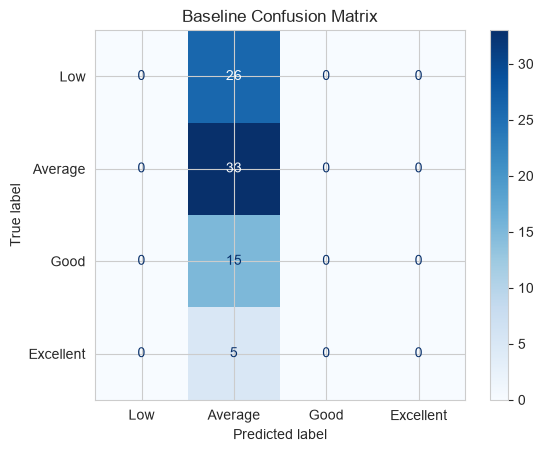

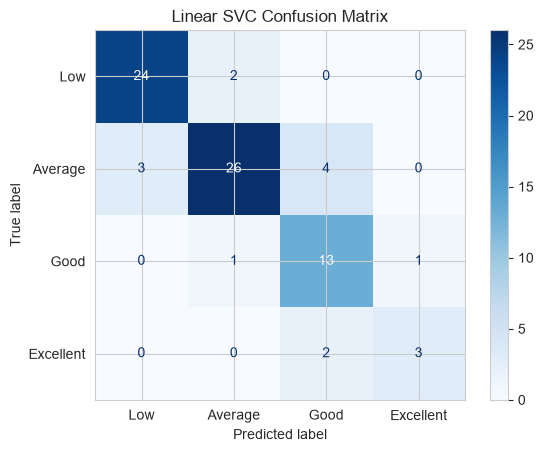

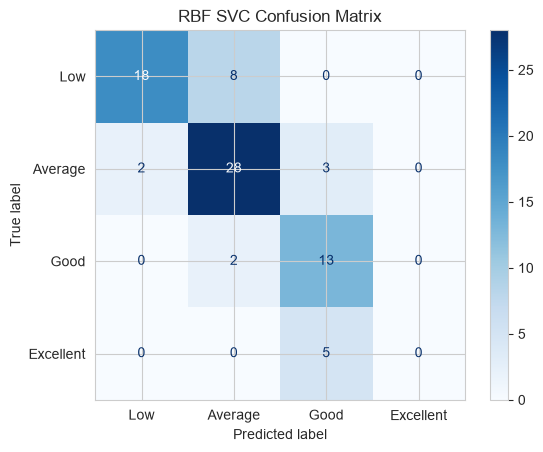

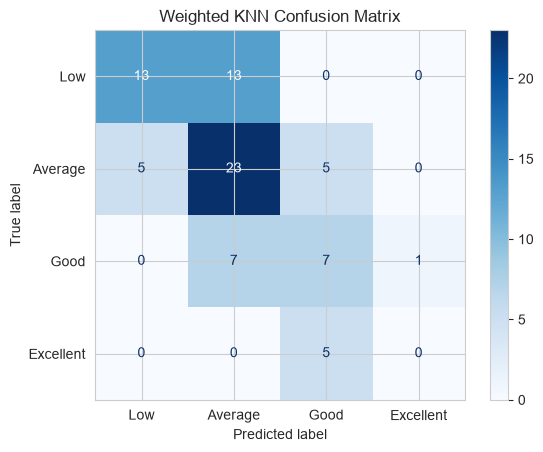

In [28]:
for name, model in all_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Low", "Average", "Good", "Excellent"]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low", "Average", "Good", "Excellent"]
    )

    display_matrix.plot(cmap="Blues")

    plt.title(name + " Confusion Matrix")
    plt.show()

In [29]:
# Remove baseline from model selection
candidate_results = comparison_df[
    comparison_df["Model"] != "Baseline"
]

# Sort using macro precision and Low Recall
candidate_results = candidate_results.sort_values(
    by=["Macro Precision", "Low Recall"],
    ascending=False
)

print("Model ranking:")
print(candidate_results[[
    "Model",
    "Macro Precision",
    "Low Recall"
]])

best_model_name = candidate_results.iloc[0]["Model"]

print("\nBest model:", best_model_name)

Model ranking:
          Model  Macro Precision  Low Recall
1    Linear SVC         0.804913    0.923077
2       RBF SVC         0.563972    0.692308
3  Weighted KNN         0.417218    0.500000

Best model: Linear SVC


In [30]:
# Save comparison table
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison table saved successfully!")

Model comparison table saved successfully!


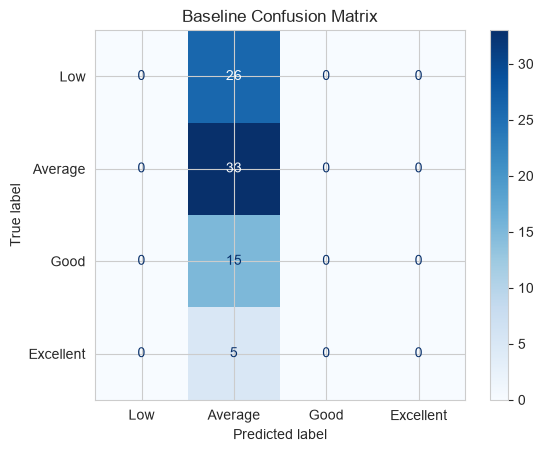

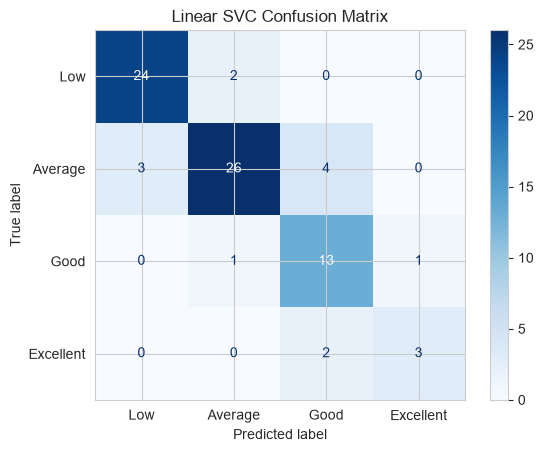

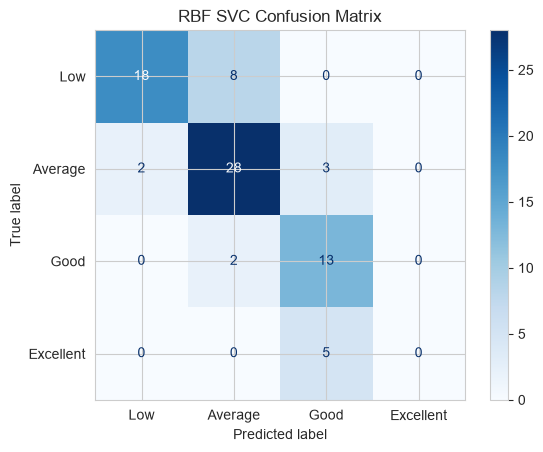

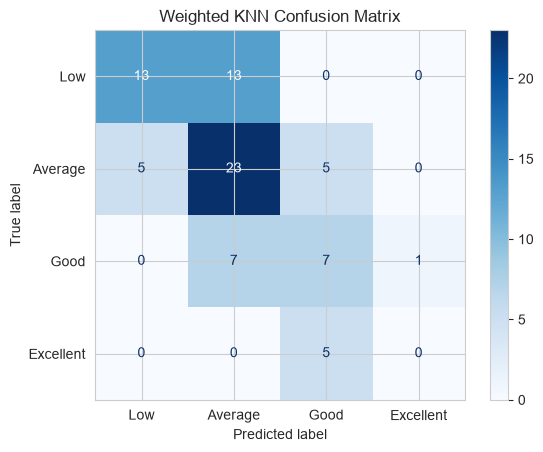

All confusion matrices saved successfully!


In [31]:
# Create a folder for results
Path("results").mkdir(exist_ok=True)

for name, model in all_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Low", "Average", "Good", "Excellent"]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low", "Average", "Good", "Excellent"]
    )

    display_matrix.plot(cmap="Blues")

    plt.title(name + " Confusion Matrix")

    # Save confusion matrix
    file_name = name.replace(" ", "_")

    plt.savefig(
        "results/" + file_name + "_confusion_matrix.png"
    )

    plt.show()
    plt.close()

print("All confusion matrices saved successfully!")

In [32]:
# Select the best trained pipeline
best_pipeline = models[best_model_name]

# Save the complete pipeline
joblib.dump(best_pipeline, "student_model.pkl")

print("Best model:", best_model_name)
print("Model saved successfully!")

Best model: Linear SVC
Model saved successfully!


In [33]:
# Load saved model
loaded_model = joblib.load("student_model.pkl")

# Take one sample from test data
sample_student = X_test.iloc[[0]]

# Predict grade category
prediction = loaded_model.predict(sample_student)

print("Student Input:")
print(sample_student)

print("\nPredicted Grade Category:", prediction[0])

Student Input:
     studytime  absences  failures  age  schoolsup  famsup  paid  activities  \
383          1         0         1   19          0       0     0           0   

     internet  higher  Medu  Fedu  First_Term  Second_Term  
383         0       1     1     1           6            5  

Predicted Grade Category: Low


In [34]:
print("Selected Model:", best_model_name)

# Get the selected Linear SVC pipeline
best_pipeline = models["Linear SVC"]

print("Model ready for saving!")

Selected Model: Linear SVC
Model ready for saving!


In [35]:
import joblib

joblib.dump(best_pipeline, "student_model.pkl")

print("student_model.pkl saved successfully!")

student_model.pkl saved successfully!


In [36]:
print("INPUT FEATURE NAMES AND DATA TYPES")
print("----------------------------------")

for column in X.columns:
    print(column, ":", X[column].dtype)

print("----------------------------------")
print("Total input features:", len(X.columns))

INPUT FEATURE NAMES AND DATA TYPES
----------------------------------
studytime : int64
absences : int64
failures : int64
age : int64
schoolsup : int64
famsup : int64
paid : int64
activities : int64
internet : int64
higher : int64
Medu : int64
Fedu : int64
First_Term : int64
Second_Term : int64
----------------------------------
Total input features: 14


In [37]:
feature_info = pd.DataFrame({
    "Feature Name": X.columns,
    "Data Type": X.dtypes.astype(str).values
})

feature_info.to_csv("feature_information.csv", index=False)

print(feature_info)
print("\nFeature information saved successfully!")

   Feature Name Data Type
0     studytime     int64
1      absences     int64
2      failures     int64
3           age     int64
4     schoolsup     int64
5        famsup     int64
6          paid     int64
7    activities     int64
8      internet     int64
9        higher     int64
10         Medu     int64
11         Fedu     int64
12   First_Term     int64
13  Second_Term     int64

Feature information saved successfully!


In [38]:
# Load the saved model
loaded_model = joblib.load("student_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [39]:
# Take one student record from test data
new_student = X_test.iloc[[0]].copy()

# Predict using the loaded model
prediction = loaded_model.predict(new_student)

print("New Student Input:")
print(new_student)

print("\nPredicted Grade Category:", prediction[0])

New Student Input:
     studytime  absences  failures  age  schoolsup  famsup  paid  activities  \
383          1         0         1   19          0       0     0           0   

     internet  higher  Medu  Fedu  First_Term  Second_Term  
383         0       1     1     1           6            5  

Predicted Grade Category: Low


In [40]:
if len(prediction) == 1:
    print("SUCCESS!")
    print("Model accepts new student input.")
    print("Prediction generated successfully.")
else:
    print("Prediction test failed.")

SUCCESS!
Model accepts new student input.
Prediction generated successfully.


In [41]:
import joblib
from pathlib import Path

model_folder = Path("models")
model_folder.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_pipeline,
    model_folder / "student_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [42]:
import pandas as pd
import joblib

# Create a manually entered student record
new_student_data = {
    "studytime": 3,
    "absences": 2,
    "failures": 0,
    "age": 16,
    "schoolsup": 0,
    "famsup": 1,
    "paid": 0,
    "activities": 1,
    "internet": 1,
    "higher": 1,
    "Medu": 3,
    "Fedu": 2,
    "First_Term": 14,
    "Second_Term": 15
}

# Arrange columns in exactly the same order as model training
new_student = pd.DataFrame([new_student_data], columns=X.columns)

# Load the saved model
loaded_model = joblib.load("models/student_model.pkl")

# Generate prediction
prediction = loaded_model.predict(new_student)

print("New Student Details:")
print(new_student)

print("\nPredicted Grade Category:", prediction[0])
print("\nNew student prediction test completed!")

New Student Details:
   studytime  absences  failures  age  schoolsup  famsup  paid  activities  \
0          3         2         0   16          0       1     0           1   

   internet  higher  Medu  Fedu  First_Term  Second_Term  
0         1       1     3     2          14           15  

Predicted Grade Category: Good

New student prediction test completed!


In [43]:
from pathlib import Path

required_files = [
    "student_model.pkl",
    "models/student_model.pkl",
    "model_comparison.csv",
    "feature_information.csv",
    "results/Baseline_confusion_matrix.png",
    "results/Linear_SVC_confusion_matrix.png",
    "results/RBF_SVC_confusion_matrix.png",
    "results/Weighted_KNN_confusion_matrix.png"
]

print("FINAL FILE VERIFICATION")
print("-----------------------")

for file in required_files:
    if Path(file).exists():
        print("FOUND:", file)
    else:
        print("MISSING:", file)

FINAL FILE VERIFICATION
-----------------------
FOUND: student_model.pkl
FOUND: models/student_model.pkl
FOUND: model_comparison.csv
FOUND: feature_information.csv
FOUND: results/Baseline_confusion_matrix.png
FOUND: results/Linear_SVC_confusion_matrix.png
FOUND: results/RBF_SVC_confusion_matrix.png
FOUND: results/Weighted_KNN_confusion_matrix.png


In [44]:
import joblib

# Load the model that Reena will use
final_model = joblib.load("models/student_model.pkl")

# Check the feature names stored by the model
print("FEATURE VERIFICATION")
print("--------------------")

print("Number of features:", len(final_model.feature_names_in_))

print("Feature names:")
print(list(final_model.feature_names_in_))

# Compare with the notebook's training features
if list(final_model.feature_names_in_) == list(X.columns):
    print("\nSUCCESS: Feature names and order match!")
else:
    print("\nERROR: Feature names or order do not match!")

FEATURE VERIFICATION
--------------------
Number of features: 14
Feature names:
['studytime', 'absences', 'failures', 'age', 'schoolsup', 'famsup', 'paid', 'activities', 'internet', 'higher', 'Medu', 'Fedu', 'First_Term', 'Second_Term']

SUCCESS: Feature names and order match!


In [45]:
print("MODEL INFORMATION")

print("Model type:", type(final_model))

print("Has preprocessing pipeline:",
      hasattr(final_model, "steps"))

print("Has prediction method:",
      hasattr(final_model, "predict"))

MODEL INFORMATION
Model type: <class 'sklearn.pipeline.Pipeline'>
Has preprocessing pipeline: True
Has prediction method: True


In [46]:
import joblib
from pathlib import Path

# Create models folder
model_folder = Path("models")
model_folder.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
model_path = model_folder / "student_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path.resolve())
print("File exists:", model_path.exists())

Model saved successfully!
Model location: C:\Users\sanji\jpcode\models\student_model.pkl
File exists: True
